# Module 8 Lab 2: Textbook Problem 9.1, AI-Assisted
## Ground truth first, then Problem 9.1

By hand (no AI): load the savings data, record shape and missing counts, and compute the mean of each column. Then prompt your AI assistant, using the Lab 1 template, to help you cluster the countries into groups by their savings behavior and visualize the result. Run its code, fix what breaks, log everything.

In [4]:
import pandas as pd

df = pd.read_csv("lifecyclesavings.csv")

print("Shape of Dataset")
print(df.shape)

print("Missing Values")
print(df.isnull().sum())

print("Column Means")
print(df.mean(numeric_only=True))

Shape of Dataset
(50, 6)
Missing Values
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64
Column Means
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     str    
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), str(1)
memory usage: 2.5 KB


#### Prompt log
You are helping with exploratory data analysis.
My CSV has columns: 
Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     str    
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) cluster the countries into groups by their savings behavior and visualize the result
Explain each step in comments.

--- Missing Data Summary ---
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64 



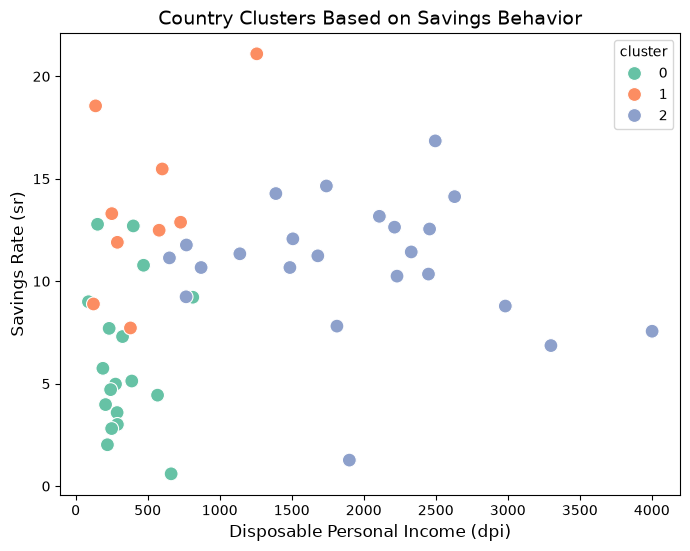

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# --- 1. Summarize missing data ---
# We use .isnull() to create a boolean mask of missing values, 
# then .sum() to count the total missing entries per column.
print("--- Missing Data Summary ---")
missing_data = df.isnull().sum()
print(missing_data, "\n")

# --- 2. Cluster the countries by savings behavior ---
# Select the numerical features that represent the savings and demographic behavior
features = ['sr', 'pop15', 'pop75', 'dpi', 'ddpi']
X = df[features]

# Standardize the data so that columns with larger numbers (like dpi) 
# do not overpower columns with smaller numbers/percentages (like sr or pop75)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize and fit a K-Means model to group the countries into 3 distinct clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

# --- Visualize the result ---
# Set the size of the plot
plt.figure(figsize=(8, 6))

# Create a scatter plot comparing Disposable Income (dpi) vs Savings Rate (sr), 
# coloring the points based on the cluster they belong to.
sns.scatterplot(data=df, x='dpi', y='sr', hue='cluster', palette='Set2', s=100)

# Add clear labels and a title
plt.title('Country Clusters Based on Savings Behavior', fontsize=14)
plt.xlabel('Disposable Personal Income (dpi)', fontsize=12)
plt.ylabel('Savings Rate (sr)', fontsize=12)

# Display the plot
plt.show()


## Verify and interpret

Verify one AI claim yourself: pick one cluster and compute its column means with your own groupby; do they actually differ from the overall means the way the AI says? Then write the human part: 3–4 sentences on what the clusters seem to represent and one caution about trusting AI-generated analysis of a technique you have not formally studied.

In [11]:
print("Overall Means")
print(df.mean(numeric_only=True))

cluster0_means = df.groupby('cluster')[['sr', 'pop15', 'pop75', 'dpi', 'ddpi']].mean().loc[0]
print("Cluster 0 Means")
print(cluster0_means)

Overall Means
sr            9.6710
pop15        35.0896
pop75         2.2930
dpi        1106.7584
ddpi          3.7576
cluster       1.1000
dtype: float64
Cluster 0 Means
sr         6.138889
pop15     44.556111
pop75      1.079444
dpi      337.153333
ddpi       2.359444
Name: 0, dtype: float64


In [12]:
cluster1_means = df.groupby('cluster')[['sr', 'pop15', 'pop75', 'dpi', 'ddpi']].mean().loc[1]
print("Cluster 1 Means")
print(cluster1_means)

Cluster 1 Means
sr        13.591111
pop15     37.492222
pop75      1.623333
dpi      483.241111
ddpi       7.662222
Name: 1, dtype: float64


In [13]:
cluster2_means = df.groupby('cluster')[['sr', 'pop15', 'pop75', 'dpi', 'ddpi']].mean().loc[2]
print("Cluster 2 Means")
print(cluster2_means)

Cluster 2 Means
sr         10.901304
pop15      26.740870
pop75       3.504783
dpi      1953.043043
ddpi        3.323913
Name: 2, dtype: float64


They do differ the way that AI says. Cluster 0 has a younger population and lower disposable income which is accurately depicted in the scatterplot. I believe that AI created the clusters based on populations economic development. 1st world countries typically start families later in life and have longer life spans which would account for cluster 2 lower under 15 population count and higher over 75 population count, as well as the larger disposable income. While in 3rd world countries you see people having children at a much younger age and shorter life span due to less healthcare access, which is shown in cluster 0. You should be careful blindly trusting AI without studying the dataset because you don't know if its clustering method is accurate or just random guesses.